# 03. MOMENT, GAF và CWT

Encoder tiền huấn luyện được đóng băng. Đầu vào ảnh 7×224×224. Các giả định 7 kênh và CWT được ghi trong `EXPERIMENT_PROTOCOL.md`. Chạy toàn bộ: `.venv/Scripts/python.exe scripts/run_all.py --skip-download`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
print('Project:', ROOT)


Project: E:\DiaGraMo-project


In [2]:
rows=[]
for p in sorted((ROOT/'data/derived').glob('*.npz')):
    d=np.load(p)
    rows.append({'representation':p.stem,'shape':str(d['X'].shape),'finite':bool(np.isfinite(d['X']).all()),'subjects':len(d['ids'])})
pd.DataFrame(rows)

,representation,shape,finite,subjects
0,cwt_efficientnet_b4,"(258, 25088)",True,258
1,cwt_resnet50,"(258, 28672)",True,258
2,cwt_vgg16,"(258, 57344)",True,258
3,cwt_vit_b_16,"(258, 10752)",True,258
4,gaf_efficientnet_b4,"(258, 25088)",True,258
5,gaf_resnet50,"(258, 28672)",True,258
6,gaf_vgg16,"(258, 57344)",True,258
7,gaf_vit_b_16,"(258, 10752)",True,258
8,kinematic,"(258, 1036)",True,258
9,moment,"(258, 14336)",True,258


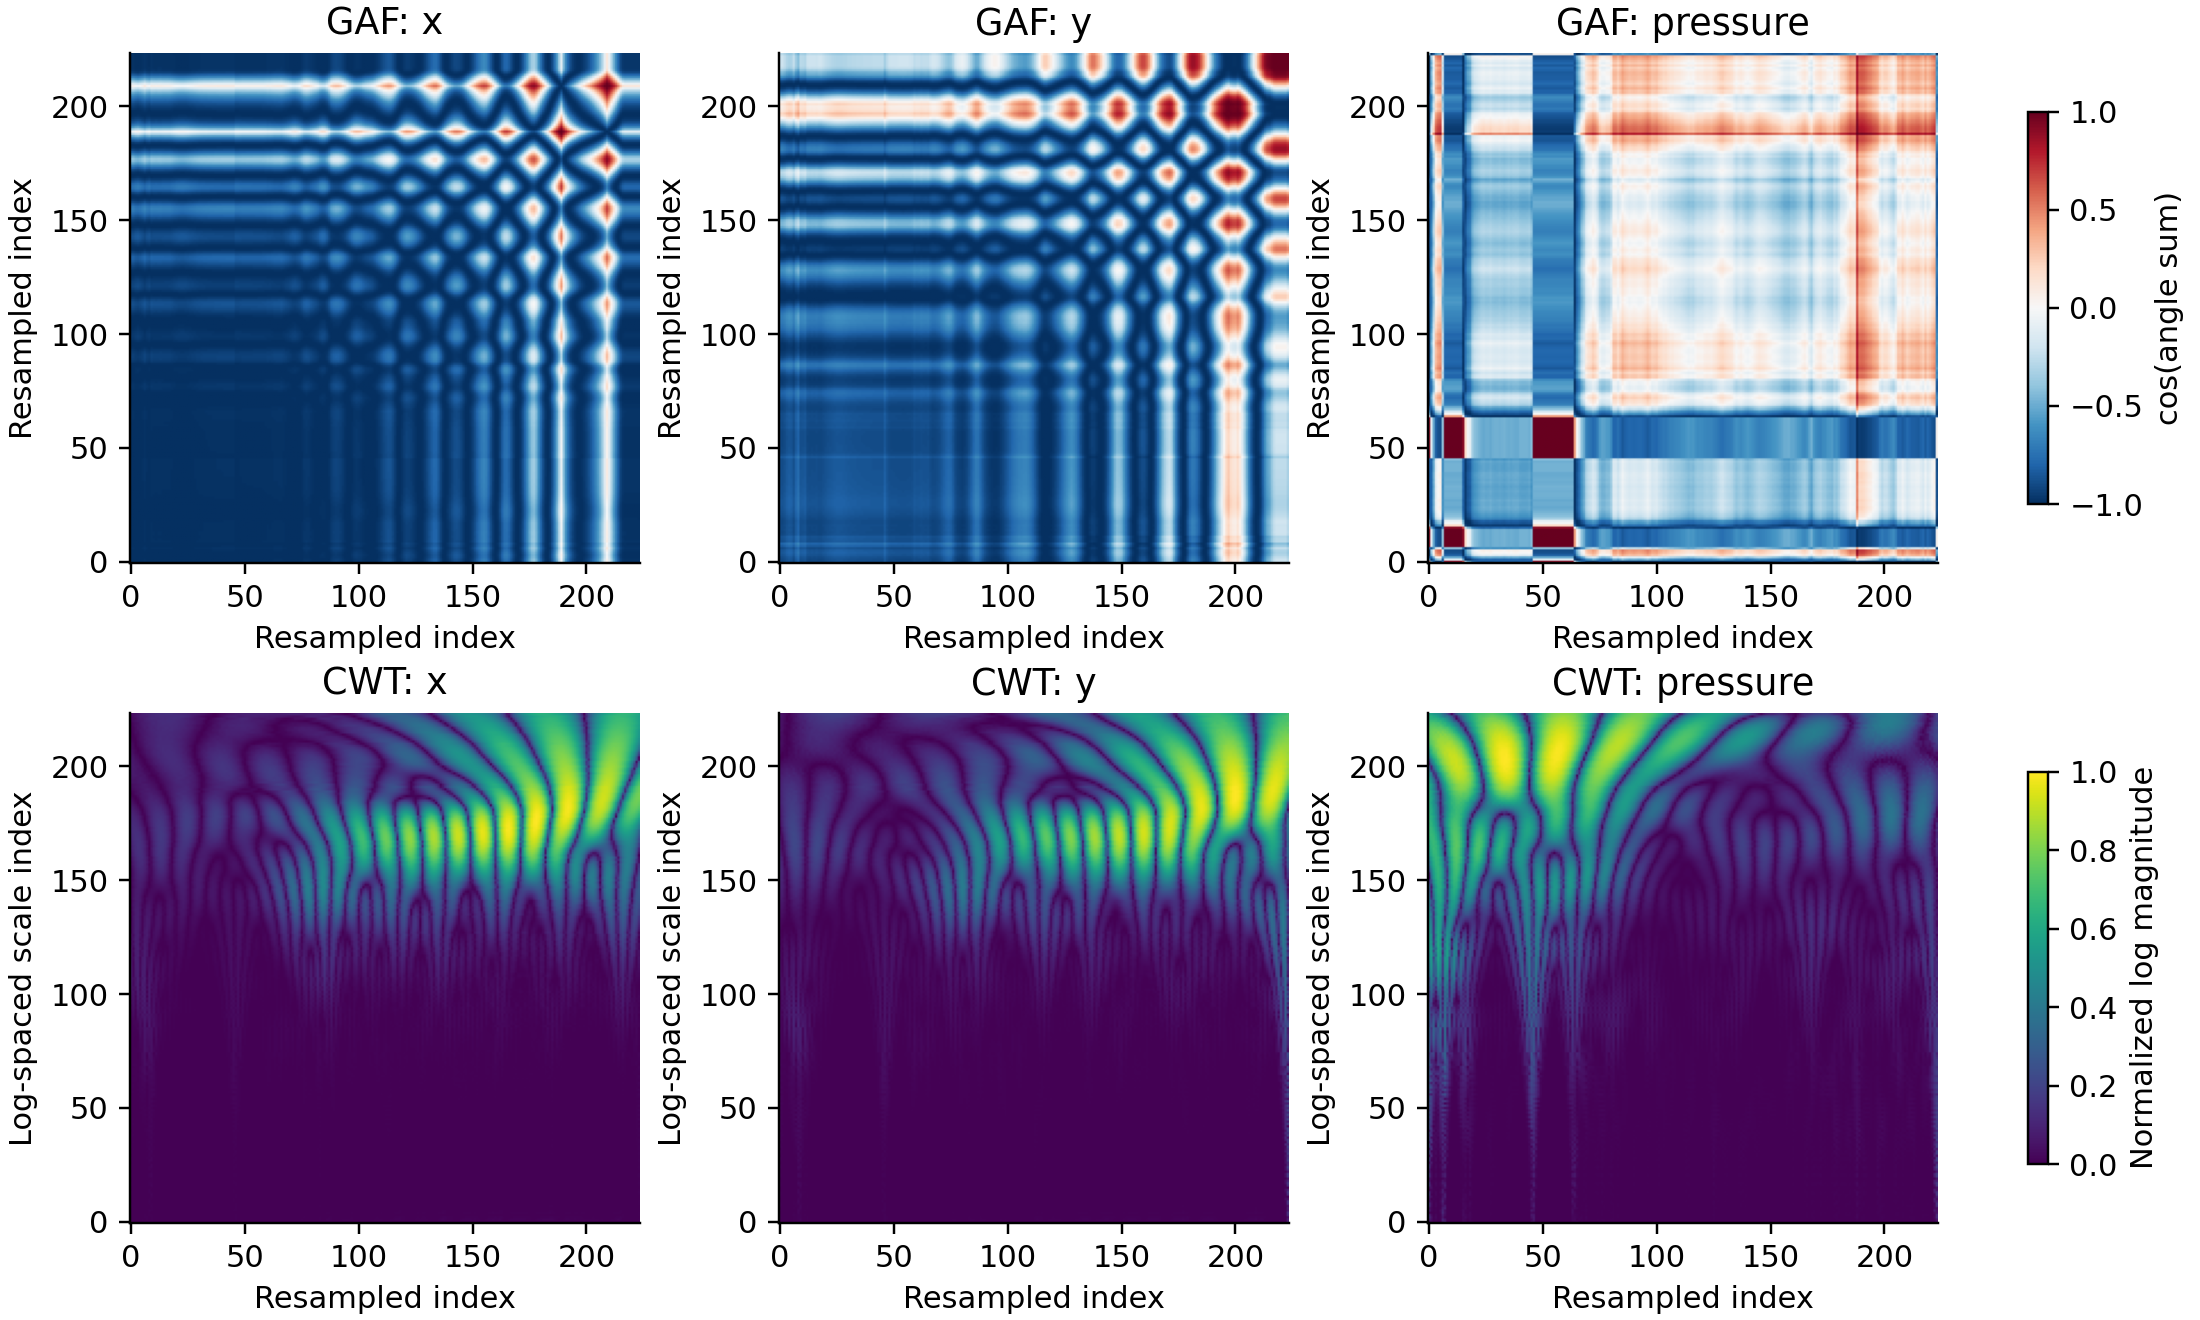

In [3]:
from IPython.display import Image,display
display(Image(filename=str(ROOT/'results/figures/representation_examples.png')))

In [4]:
pd.DataFrame([json.loads(p.read_text()) for p in sorted((ROOT/'data/derived').glob('*.metadata.json'))])

,representation,encoder,dimension_per_task,dimension_per_subject,subjects,frozen,device,precision,channel_adaptation,image_normalization,seconds
0,cwt,efficientnet_b4,1792,25088,258,True,cuda,float32,"sum RGB kernels / 7, repeated 7 channels","(image[0,1] - 0.449)/0.226",75.860253
1,cwt,resnet50,2048,28672,258,True,cuda,float32,"sum RGB kernels / 7, repeated 7 channels","(image[0,1] - 0.449)/0.226",38.101888
2,cwt,vgg16,4096,57344,258,True,cuda,float32,"sum RGB kernels / 7, repeated 7 channels","(image[0,1] - 0.449)/0.226",50.409070
3,cwt,vit_b_16,768,10752,258,True,cuda,float32,"sum RGB kernels / 7, repeated 7 channels","(image[0,1] - 0.449)/0.226",114.857598
4,gaf,efficientnet_b4,1792,25088,258,True,cuda,float32,"sum RGB kernels / 7, repeated 7 channels","(image[0,1] - 0.449)/0.226",44.403960
5,gaf,resnet50,2048,28672,258,True,cuda,float32,"sum RGB kernels / 7, repeated 7 channels","(image[0,1] - 0.449)/0.226",42.182033
6,gaf,vgg16,4096,57344,258,True,cuda,float32,"sum RGB kernels / 7, repeated 7 channels","(image[0,1] - 0.449)/0.226",50.642793
7,gaf,vit_b_16,768,10752,258,True,cuda,float32,"sum RGB kernels / 7, repeated 7 channels","(image[0,1] - 0.449)/0.226",117.526506
8,moment,AutonLab/MOMENT-1-large,1024,14336,258,True,cuda,float32,"sum RGB kernels / 7, repeated 7 channels","(image[0,1] - 0.449)/0.226",829.005036
